# Living at the Top of the Hill
## Residential Elevation and VO2 Max
### *Research question:* Among Boston Marathon finishers (2015-2017), is there a measurable association between home-city elevation and estimated VO2max, controlling for age and sex?

In [10]:
# dependencies
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import os

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import time

import statsmodels.formula.api as smf
import statsmodels.api as sm

In [11]:
# load data
df_2015 = pd.read_csv('./marathon_results_2015.csv')
df_2016 = pd.read_csv('./marathon_results_2016.csv')
df_2017 = pd.read_csv('./marathon_results_2017.csv')

df_2015.head()

,Unnamed: 0,Bib,Name,Age,M/F,City,State,Country,Citizen,Unnamed: 9,...,25K,30K,35K,40K,Pace,Proj Time,Official Time,Overall,Gender,Division
0,0,3,"Desisa, Lelisa",25,M,Ambo,NaN,ETH,NaN,NaN,...,1:16:07,1:32:00,1:47:59,2:02:39,0:04:56,-,2:09:17,1,1,1
1,1,4,"Tsegay, Yemane Adhane",30,M,Addis Ababa,NaN,ETH,NaN,NaN,...,1:16:07,1:31:59,1:47:59,2:02:42,0:04:58,-,2:09:48,2,2,2
2,2,8,"Chebet, Wilson",29,M,Marakwet,NaN,KEN,NaN,NaN,...,1:16:07,1:32:00,1:47:59,2:03:01,0:04:59,-,2:10:22,3,3,3
3,3,11,"Kipyego, Bernard",28,M,Eldoret,NaN,KEN,NaN,NaN,...,1:16:07,1:32:00,1:48:03,2:03:47,0:05:00,-,2:10:47,4,4,4
4,4,10,"Korir, Wesley",32,M,Kitale,NaN,KEN,NaN,NaN,...,1:16:07,1:32:00,1:47:59,2:03:27,0:05:00,-,2:10:49,5,5,5


In [12]:
df_2016.head()

,Bib,Name,Age,M/F,City,State,Country,Citizen,Unnamed: 8,5K,...,25K,30K,35K,40K,Pace,Proj Time,Official Time,Overall,Gender,Division
0,5,"Hayle, Lemi Berhanu",21,M,Addis Ababa,NaN,ETH,NaN,NaN,0:15:47,...,1:19:15,1:34:17,1:50:24,2:05:59,0:05:04,2:12:45,2:12:45,1,1,1
1,1,"Desisa, Lelisa",26,M,Ambo,NaN,ETH,NaN,NaN,0:15:47,...,1:19:15,1:34:17,1:50:24,2:05:59,0:05:06,2:13:32,2:13:32,2,2,2
2,6,"Tsegay, Yemane Adhane",31,M,Addis Ababa,NaN,ETH,NaN,NaN,0:15:46,...,1:19:15,1:34:45,1:50:48,2:06:47,0:05:07,2:14:02,2:14:02,3,3,3
3,11,"Korir, Wesley",33,M,Kitale,NaN,KEN,NaN,NaN,0:15:46,...,1:19:16,1:34:45,1:50:48,2:06:47,0:05:07,2:14:05,2:14:05,4,4,4
4,14,"Lonyangata, Paul",23,M,Eldoret,NaN,KEN,NaN,NaN,0:15:46,...,1:19:18,1:34:46,1:51:30,2:08:11,0:05:11,2:15:45,2:15:45,5,5,5


In [13]:
df_2017.head()

,Unnamed: 0,Bib,Name,Age,M/F,City,State,Country,Citizen,Unnamed: 9,...,25K,30K,35K,40K,Pace,Proj Time,Official Time,Overall,Gender,Division
0,0,11,"Kirui, Geoffrey",24,M,Keringet,NaN,KEN,NaN,NaN,...,1:16:59,1:33:01,1:48:19,2:02:53,0:04:57,-,2:09:37,1,1,1
1,1,17,"Rupp, Galen",30,M,Portland,OR,USA,NaN,NaN,...,1:16:59,1:33:01,1:48:19,2:03:14,0:04:58,-,2:09:58,2,2,2
2,2,23,"Osako, Suguru",25,M,Machida-City,NaN,JPN,NaN,NaN,...,1:17:00,1:33:01,1:48:31,2:03:38,0:04:59,-,2:10:28,3,3,3
3,3,21,"Biwott, Shadrack",32,M,Mammoth Lakes,CA,USA,NaN,NaN,...,1:17:00,1:33:01,1:48:58,2:04:35,0:05:03,-,2:12:08,4,4,4
4,4,9,"Chebet, Wilson",31,M,Marakwet,NaN,KEN,NaN,NaN,...,1:16:59,1:33:01,1:48:41,2:05:00,0:05:04,-,2:12:35,5,5,5


## EDA
* nulls
* duplicates
* datatypes
* listed column names

In [14]:
def explore_datasets(*dfs, names=None):
    """
    Quick EDA for df(s): shape, dtypes, nulls, duplicates, and cardinality of object columns
    Pass names= to label output
    """
    if names is None:
        names = [f'df{i+1}' for i in range(len(dfs))]

    for name, df in zip(names, dfs):
        print(f'\n{'='*60}')
        print(f'{name}')
        print(f'{'='*60}')
        print(f'shape: {df.shape[0]:,} rows x {df.shape[1]} cols')

        print('\ncolumns & dtypes:')
        print(df.dtypes)

        print('\nnulls (count / % of rows):')
        null_counts = df.isnull().sum()
        null_pct = (null_counts / len(df) * 100).round(1)
        null_summary = pd.DataFrame({'n_null': null_counts, 'pct_null': null_pct})
        print(null_summary[null_summary['n_null'] > 0].sort_values('n_null', ascending=False))

        dupes = df.duplicated().sum()
        print(f'\nfully duplicate rows: {dupes}')

        print('\ncardinality of object columns:')
        obj_cols = df.select_dtypes(include='object').columns
        for col in obj_cols:
            print(f' {col}: {df[col].nunique():,} unique values')

        print('\nnumeric summary:')
        print(df.describe())

explore_datasets(df_2015, df_2016, df_2017, names=['2015', '2016', '2017'])


2015
shape: 26,598 rows x 25 cols

columns & dtypes:
Unnamed: 0        int64
Bib              object
Name             object
Age               int64
M/F              object
City             object
State            object
Country          object
Citizen          object
Unnamed: 9       object
5K               object
10K              object
15K              object
20K              object
Half             object
25K              object
30K              object
35K              object
40K              object
Pace             object
Proj Time        object
Official Time    object
Overall           int64
Gender            int64
Division          int64
dtype: object

nulls (count / % of rows):
            n_null  pct_null
Unnamed: 9   26531      99.7
Citizen      25534      96.0
State         2551       9.6

fully duplicate rows: 0

cardinality of object columns:
 Bib: 26,598 unique values
 Name: 26,540 unique values
 M/F: 2 unique values
 City: 5,616 unique values
 State: 69 unique values
 C

In [15]:
# column names
f' {df_2015.columns.tolist()} {df_2016.columns.tolist()} {df_2017.columns.tolist()}'

" ['Unnamed: 0', 'Bib', 'Name', 'Age', 'M/F', 'City', 'State', 'Country', 'Citizen', 'Unnamed: 9', '5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Pace', 'Proj Time', 'Official Time', 'Overall', 'Gender', 'Division'] ['Bib', 'Name', 'Age', 'M/F', 'City', 'State', 'Country', 'Citizen', 'Unnamed: 8', '5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Pace', 'Proj Time', 'Official Time', 'Overall', 'Gender', 'Division'] ['Unnamed: 0', 'Bib', 'Name', 'Age', 'M/F', 'City', 'State', 'Country', 'Citizen', 'Unnamed: 9', '5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Pace', 'Proj Time', 'Official Time', 'Overall', 'Gender', 'Division']"

## Data Cleaning
* add year tags before merging Boston Marathon datasets
* remove unnecessary columns and standardize to all lowercase names
* `.info` sanity check on merged dataframe
* filter to only include US participants

In [16]:
# tag each df with year
df_2015["year"] = 2015
df_2016["year"] = 2016
df_2017["year"] = 2017

# df_2015.head()

In [17]:
# merge dfs, remove unnecessary columns, and rename to all lowercase
keep_cols = ["Bib", "Name", "Age", "M/F", "City", "State", "Country", "Official Time", "year"]

df_2015 = df_2015[keep_cols]
df_2016 = df_2016[keep_cols]
df_2017 = df_2017[keep_cols]

marathon_df = pd.concat([df_2015, df_2016, df_2017], ignore_index=True)
marathon_df.columns = [x.lower() for x in marathon_df.columns]

In [18]:
marathon_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79638 entries, 0 to 79637
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   bib            79638 non-null  object
 1   name           79638 non-null  object
 2   age            79638 non-null  int64 
 3   m/f            79638 non-null  object
 4   city           79637 non-null  object
 5   state          70645 non-null  object
 6   country        79638 non-null  object
 7   official time  79638 non-null  object
 8   year           79638 non-null  int64 
dtypes: int64(2), object(7)
memory usage: 5.5+ MB


In [19]:
# filter to only include US participants only
marathon_df = marathon_df[marathon_df['country'] == 'USA']

marathon_df.head()

,bib,name,age,m/f,city,state,country,official time,year
6,14,"Ritzenhein, Dathan",32,M,Rockford,MI,USA,2:11:20,2015
7,1,"Keflezighi, Meb",39,M,San Diego,CA,USA,2:12:42,2015
10,22,"Tegenkamp, Matt",33,M,Portland,OR,USA,2:13:52,2015
11,19,"Eggleston, Jeffrey",30,M,Boulder,CO,USA,2:14:17,2015
13,20,"Arciniaga, Nicholas",31,M,Flagstaff,AZ,USA,2:18:02,2015


In [20]:
marathon_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 64474 entries, 6 to 79637
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   bib            64474 non-null  object
 1   name           64474 non-null  object
 2   age            64474 non-null  int64 
 3   m/f            64474 non-null  object
 4   city           64474 non-null  object
 5   state          64474 non-null  object
 6   country        64474 non-null  object
 7   official time  64474 non-null  object
 8   year           64474 non-null  int64 
dtypes: int64(2), object(7)
memory usage: 4.9+ MB


## Geocode and assign elevation
* collect unique locations (7297)
* test request before making 7297 calls
* *The initial run of geocode_row takes a minimum of the number of unique city/state pairs in seconds. The first run took ~5 hours with 7297 pairs to geocode*
* save responses to `city_coordinates.csv`
* inspect failed values for handling
* define function to map geocode coordinates to elevation with API calls
* if `elevation_m` does not exist as a column in `unique_locations`, run `get_elevation` and add to `city_coordinates.csv`


In [29]:
unique_locations = (
    marathon_df.loc[marathon_df["country"] == "USA", ["city", "state"]]
    .drop_duplicates()
    .reset_index(drop=True)
)
print(f'{len(unique_locations)} unique city/state pairs to geocode')

7297 unique city/state pairs to geocode


In [30]:
test = requests.get(
    'https://epqs.nationalmap.gov/v1/json', params={'x': -104.9903, 'y': 39.7392, 'units': 'Meters', 
'wkid': 4326, 'includeDate': 'false'}, timeout=10,
)
test.json() # expect Denver, CO ~1600m under a 'value' key

{'location': {'x': -104.9903,
  'y': 39.7392,
  'spatialReference': {'wkid': 4326, 'latestWkid': 4326}},
 'locationId': 0,
 'value': '1596.446899414',
 'rasterId': 52280,
 'resolution': 1}

In [31]:
# geocode city, state pairs
if os.path.exists('city_coordinates.csv'):
    unique_locations = pd.read_csv('city_coordinates.csv')
    print(f'loaded cached geocoding results: {unique_locations['lat'].isnull().sum()} unresolved')
else:
    geolocator = Nominatim(user_agent="topofthehill")
    geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1, max_retries=2)

    def geocode_row(row):
        location = geocode(f'{row['city']}, {row['state']}, USA')
        if location:
            return pd.Series({'lat': location.latitude, 'lon': location.longitude})
        else:
            return pd.Series({'lat': None, 'lon': None})

    unique_locations[['lat', 'lon']] = unique_locations.apply(geocode_row, axis=1)

    # cache immediately
    unique_locations.to_csv('city_coordinates.csv', index=False)

    print(f'failed to geocode: {unique_locations['lat'].isnull().sum()} rows')
unique_locations[unique_locations['lat'].isnull()]

loaded cached geocoding results: 127 unresolved


,city,state,lat,lon,elevation_m
327,Saint Clarsville,OH,NaN,NaN,NaN
344,Amemae,CA,NaN,NaN,NaN
1103,Chciago,IL,NaN,NaN,NaN
1263,San Francsico,CA,NaN,NaN,NaN
1654,Winton Salem,NC,NaN,NaN,NaN
...,...,...,...,...,...
7161,Germantwon,MD,NaN,NaN,NaN
7166,Fitchburgh,MA,NaN,NaN,NaN
7170,Wentzvile,MO,NaN,NaN,NaN
7194,Wycokoff,NJ,NaN,NaN,NaN


In [32]:
failed_pairs = unique_locations[unique_locations['lat'].isnull()]
affected_rows = marathon_df.merge(failed_pairs[['city', 'state']], on=['city', 'state'])
print(f'{len(affected_rows)} finisher rows affected({len(affected_rows) / len(marathon_df) * 100:.1f}% of total)')

135 finisher rows affected(0.2% of total)


In [33]:
failed_pairs[['city', 'state']].sort_values('state').head()

,city,state
2289,Dpo,AA
5052,Fpo,AE
3912,Birmimgham,AL
6807,Fpo,AP
2857,F P O,AP


In [34]:
# define map from geocode coordinates to elevation

def get_elevation(lat, lon, retries=3):
        if pd.isnull(lat):
            return np.nan
        url = "https://epqs.nationalmap.gov/v1/json"
        params = {"x": lon, "y": lat, "units": "Meters", "wkid": 4326, "includeDate": "false"}
        for attempt in range(retries):
            try:
                resp = requests.get(url, params=params, timeout=20)
                resp.raise_for_status()
                elevation = float(resp.json()['value'])
                return np.nan if elevation < -1000 else elevation
            except Exception as e:
                if attempt < retries - 1:
                    time.sleep(2 * (attempt + 1))
                else:
                    print(f'failed for ({lat}, {lon}) after {retries} attempts: {e}')
                    return np.nan

In [35]:
# map geocode coordinates to elevation

if 'elevation_m' not in unique_locations.columns or unique_locations['elevation_m'].isnull().all():
    
    unique_locations['elevation_m'] = unique_locations.apply(
        lambda r: get_elevation(r['lat'], r['lon']), axis=1
    )
    
    unique_locations.to_csv('city_coordinates.csv', index=False)
else:
    print('elevation already computed, skipping')

elevation already computed, skipping


In [36]:
coordinates = pd.read_csv('city_coordinates.csv')
coordinates.head()

,city,state,lat,lon,elevation_m
0,Rockford,MI,43.119721,-85.559604,213.974716
1,San Diego,CA,32.717420,-117.162772,15.195767
2,Portland,OR,45.520247,-122.674194,10.319912
3,Boulder,CO,40.014986,-105.270545,1621.381836
4,Flagstaff,AZ,35.198752,-111.651822,2106.162842


## Sanity check
* df length before and after merge and dropping columns

In [37]:
marathon_df = marathon_df.merge(unique_locations, on=["city", "state"], how="left")

In [38]:
n_before = len(marathon_df)
marathon_df = marathon_df.dropna(subset=['elevation_m']).reset_index(drop=True)
n_after = len(marathon_df)

print(f'dropped {n_before - n_after} rows ({(n_before - n_after) / n_before * 100:.2f}%) due to unresolved elevation lookup')

dropped 496 rows (0.77%) due to unresolved elevation lookup


In [39]:
marathon_df.shape
# marathon_df['elevation_m'].isnull().sum()

(63978, 12)

In [40]:
marathon_df.columns.tolist()

['bib',
 'name',
 'age',
 'm/f',
 'city',
 'state',
 'country',
 'official time',
 'year',
 'lat',
 'lon',
 'elevation_m']

In [41]:
marathon_df.isnull().sum()

bib              0
name             0
age              0
m/f              0
city             0
state            0
country          0
official time    0
year             0
lat              0
lon              0
elevation_m      0
dtype: int64

## Data Cleaning Round 2 
* remove duplicate names, keeping the most recent year
* add VO2 max column from VDOT formula

In [42]:
# same-year duplicate names -- almost certainly different people sharing a common name, not repeat runners
same_year_dupes = marathon_df.groupby(["year", "name"]).size()
print(f"same-year duplicate name instances: {(same_year_dupes > 1).sum()}")

# cross-year repeats -- same name showing up in more than one year's finisher list
runner_year_counts = marathon_df.groupby("name")["year"].nunique()
repeat_runners = runner_year_counts[runner_year_counts > 1]
affected_rows = marathon_df["name"].isin(repeat_runners.index).sum()

print(f"{len(repeat_runners)} names appear in more than one year")
print(f"{affected_rows} finisher rows belong to a repeat runner ({affected_rows / len(marathon_df) * 100:.1f}% of total)")

same-year duplicate name instances: 131
8410 names appear in more than one year
18877 finisher rows belong to a repeat runner (29.5% of total)


In [43]:
marathon_df = (
    marathon_df.sort_values("year")
    .drop_duplicates(subset="name", keep="last")
    .reset_index(drop=True)
)
print(f"{len(marathon_df)} unique finishers after deduplication")

53450 unique finishers after deduplication


## VO2 max estimate based on Daniels & Gilbert (1979) VDOT formula
 * standard method and calibrated specifically on competitive distance runners:
 * v = 42195 / official_time_minutes          # race velocity, m/min
 * VO2 = -4.60 + 0.182258*v + 0.000104*v**2
 * pct_max = 0.8 + 0.1894393*exp(-0.012778*t) + 0.2989558*exp(-0.1932605*t)   # t = time in minutes
 * VDOT = VO2 / pct_max

In [44]:
# VDOT VO2max formula

marathon_df['official_time_minutes'] = pd.to_timedelta(marathon_df['official time']).dt.total_seconds() / 60

t = marathon_df['official_time_minutes']
v = 42195 / t # marathon distance in meters / time in minutes = pace, m/min
vo2 = -4.60 + 0.182258 * v + 0.000104 * v**2
pct_max = 0.8 + 0.1894393 * np.exp(-0.012778 * t) + 0.2989558 * np.exp(-0.1932605 * t)

marathon_df['vdot'] = vo2 / pct_max
marathon_df['vdot'].describe()

count    53450.000000
mean        40.019251
std          8.248380
min         10.081093
25%         34.372487
50%         39.948678
75%         45.246015
max         78.390450
Name: vdot, dtype: float64

## Visual Analysis
* create elevation bins
* visualize elevation skewness (raw vs log)
* visualize VDOT vs elevation (raw vs log)
* age, VDOT, elevation histograms

In [27]:
elevation_bins = [-1, 500, 1500, float('inf')]
elevation_labels = ['sea_level', 'moderate', 'high']

marathon_df['elevation_bracket'] = pd.cut(
    marathon_df['elevation_m'], bins=elevation_bins, labels=elevation_labels
)
marathon_df['elevation_bracket'].value_counts().sort_index()

elevation_bracket
sea_level    49418
moderate      2334
high          1677
Name: count, dtype: int64

In [28]:
check_cities = ["Boulder", "Denver", "Colorado Springs", "Flagstaff", "Albuquerque", "Salt Lake City"]
marathon_df[marathon_df["city"].isin(check_cities)][["city", "state", "elevation_m", "elevation_bracket"]].drop_duplicates()

,city,state,elevation_m,elevation_bracket
14,Salt Lake City,UT,1299.652466,moderate
23,Denver,CO,1608.218506,high
55,Boulder,CO,1621.381836,high
57,Colorado Springs,CO,1831.583130,high
101,Flagstaff,AZ,2106.162842,high
917,Albuquerque,NM,1510.456543,high
18020,Denver,NC,273.927521,sea_level
46146,Denver,CA,39.448647,sea_level
52801,Denver,PA,126.754837,sea_level


In [29]:
marathon_df['elevation_m_clipped'] = marathon_df['elevation_m'].clip(lower=0)
marathon_df['log_elevation'] = np.log1p(marathon_df['elevation_m_clipped'])

elevation_m skewness: 3.36
min elevation: -12.8


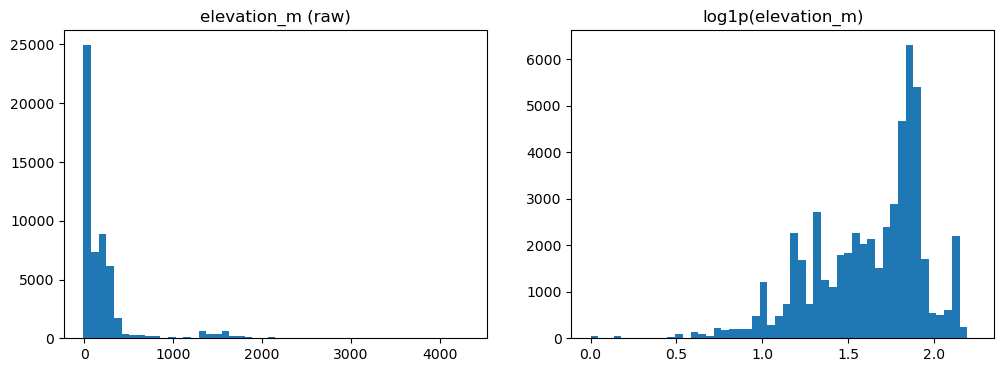

In [35]:
print(f"elevation_m skewness: {marathon_df['elevation_m'].skew():.2f}")
print(f"min elevation: {marathon_df['elevation_m'].min():.1f}")  # confirms log1p is safe (no values <= -1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(marathon_df['elevation_m'], bins=50)
axes[0].set_title('elevation_m (raw)')
axes[1].hist(np.log1p(marathon_df['log_elevation']), bins=50)
axes[1].set_title('log1p(elevation_m)')
plt.show()

In [41]:
neg_elev = marathon_df[marathon_df['elevation_m'] < 0]
print(f"{len(neg_elev)} rows with negative elevation")
neg_elev[['city', 'state', 'elevation_m']].drop_duplicates().sort_values('elevation_m')

46 rows with negative elevation


,city,state,elevation_m
24659,El Centro,CA,-12.805337
37526,Heber,CA,-4.577633
45195,Harvey,LA,-3.896795
31229,Indio,CA,-2.600036
26316,Waquoit,MA,-2.100000
36598,Tenants Harbor,ME,-1.800000
425,Metairie,LA,-1.777049
16381,Old Orchard Beach,ME,-1.600000
8902,Niantic,CT,-1.158242
21545,North Palm Beach,FL,-0.914402


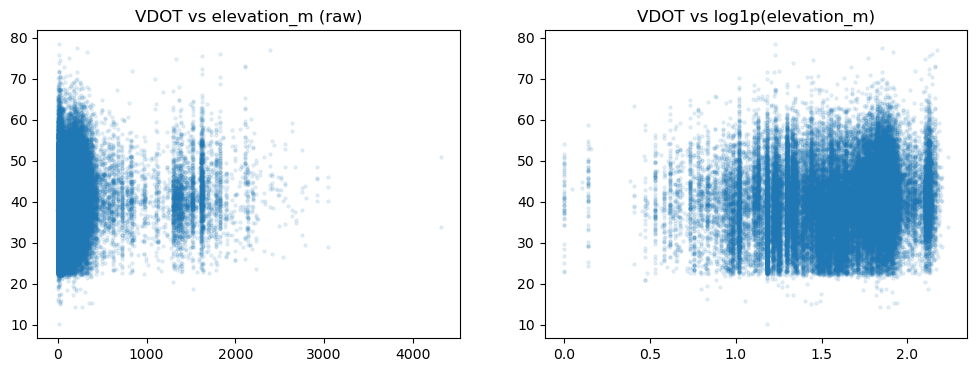

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(marathon_df['elevation_m'], marathon_df['vdot'], alpha=0.1, s=5)
axes[0].set_title('VDOT vs elevation_m (raw)')
axes[1].scatter(np.log1p(marathon_df['log_elevation']), marathon_df['vdot'], alpha=0.1, s=5)
axes[1].set_title('VDOT vs log1p(elevation_m)')
plt.show()

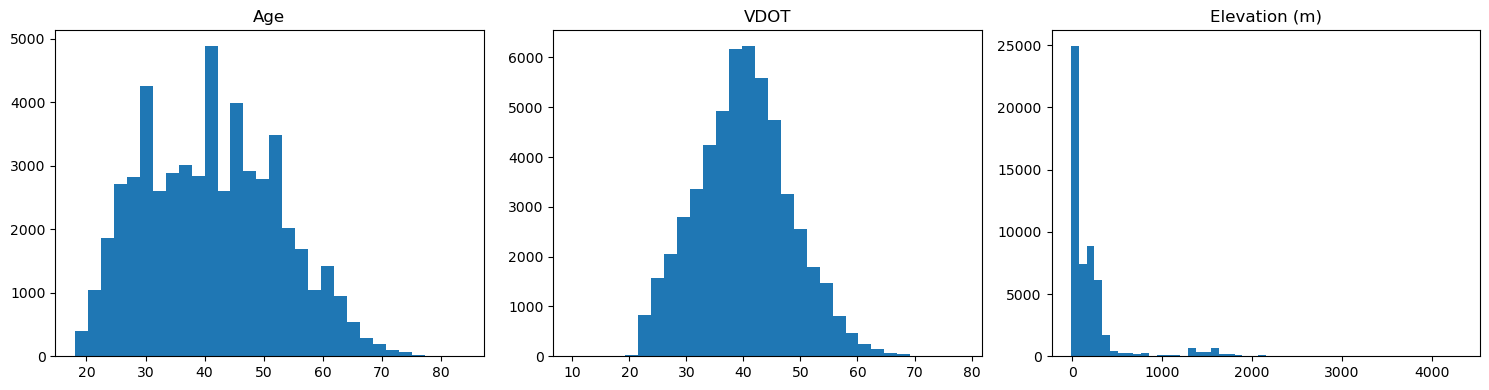

,age,vdot,elevation_m
count,53450.000000,53450.000000,53450.000000
mean,41.152591,40.019251,208.912837
std,11.482971,8.248380,361.840152
min,18.000000,10.081093,-12.805337
25%,32.000000,34.372487,19.121140
50%,41.000000,39.948678,92.274986
75%,50.000000,45.246015,232.716949
max,84.000000,78.390450,4315.540527


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(marathon_df['age'], bins=30)
axes[0].set_title('Age')
axes[1].hist(marathon_df['vdot'], bins=30)
axes[1].set_title('VDOT')
axes[2].hist(marathon_df['elevation_m'], bins=50)
axes[2].set_title('Elevation (m)')
plt.tight_layout()
plt.show()

marathon_df[['age', 'vdot', 'elevation_m']].describe()

## Analysis
* Pearson's correlaton for age, VDOT, and elevation
* VDOT by sex
* OLS reduced model with VDOT, age, and sex
* OLS full model with VDOT, age, sex, and `log_elevation`

In [39]:
marathon_df[['age', 'vdot', 'elevation_m']].corr()

,age,vdot,elevation_m
age,1.000000,-0.246759,0.048338
vdot,-0.246759,1.000000,0.093257
elevation_m,0.048338,0.093257,1.000000


In [40]:
marathon_df.groupby('m/f')['vdot'].describe()

,count,mean,std,min,25%,50%,75%,max
m/f,,,,,,,,
F,26325.0,37.655416,6.675314,10.081093,33.207231,38.280417,42.270488,70.121248
M,27125.0,42.313369,8.951846,14.181686,35.946190,42.464995,48.685034,78.390450


In [37]:
reduced_model = smf.ols("vdot ~ age + Q('m/f')", data=marathon_df).fit()
print(reduced_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   vdot   R-squared:                       0.176
Model:                            OLS   Adj. R-squared:                  0.176
Method:                 Least Squares   F-statistic:                     5726.
Date:                Tue, 21 Jul 2026   Prob (F-statistic):               0.00
Time:                        22:53:32   Log-Likelihood:            -1.8343e+05
No. Observations:               53450   AIC:                         3.669e+05
Df Residuals:                   53447   BIC:                         3.669e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        46.5048      0.121    384.879

In [38]:
full_model = smf.ols("vdot ~ age + Q('m/f') + log_elevation", data=marathon_df).fit()
print(full_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   vdot   R-squared:                       0.203
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     4547.
Date:                Tue, 21 Jul 2026   Prob (F-statistic):               0.00
Time:                        22:53:45   Log-Likelihood:            -1.8255e+05
No. Observations:               53450   AIC:                         3.651e+05
Df Residuals:                   53446   BIC:                         3.651e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        43.3148      0.141    308.064

In [46]:
full_model_robust = smf.ols("vdot ~ age + Q('m/f') + log_elevation", data=marathon_df).fit(cov_type='HC3')
print(full_model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                   vdot   R-squared:                       0.203
Model:                            OLS   Adj. R-squared:                  0.203
Method:                 Least Squares   F-statistic:                     4265.
Date:                Tue, 21 Jul 2026   Prob (F-statistic):               0.00
Time:                        23:24:30   Log-Likelihood:            -1.8255e+05
No. Observations:               53450   AIC:                         3.651e+05
Df Residuals:                   53446   BIC:                         3.651e+05
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        43.3148      0.155    280.210

In [39]:
comparison = sm.stats.anova_lm(reduced_model, full_model)
print(comparison)
print(f"R² change: {full_model.rsquared - reduced_model.rsquared:.4f}")

   df_resid           ssr  df_diff       ss_diff            F  Pr(>F)
0   53447.0  2.994749e+06      0.0           NaN          NaN     NaN
1   53446.0  2.897042e+06      1.0  97706.075007  1802.527584     0.0
R² change: 0.0269


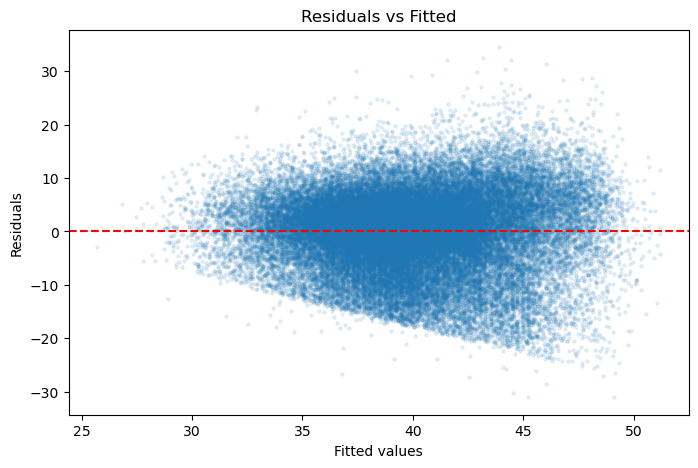

In [42]:
fitted = full_model.fittedvalues
residuals = full_model.resid

plt.figure(figsize=(8, 5))
plt.scatter(fitted, residuals, alpha=0.1, s=5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted')
plt.show()

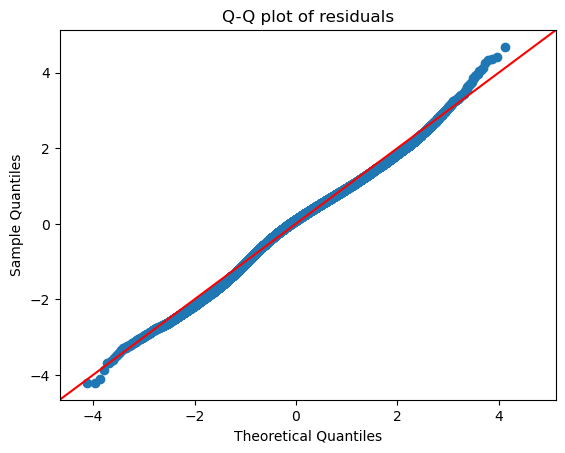

In [43]:
sm.qqplot(residuals, line='45', fit=True)
plt.title('Q-Q plot of residuals')
plt.show()

In [44]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

exog = full_model.model.exog
exog_names = full_model.model.exog_names

vif_data = pd.DataFrame({
    'variable': exog_names,
    'VIF': [variance_inflation_factor(exog, i) for i in range(exog.shape[1])]
})
print(vif_data)

        variable        VIF
0      Intercept  19.493835
1  Q('m/f')[T.M]   1.043635
2            age   1.058857
3  log_elevation   1.015081


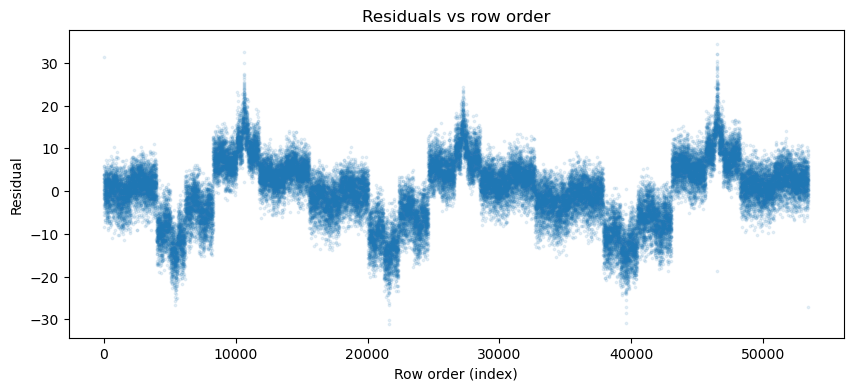

In [45]:
plt.figure(figsize=(10, 4))
plt.scatter(range(len(residuals)), residuals, alpha=0.1, s=3)
plt.xlabel('Row order (index)')
plt.ylabel('Residual')
plt.title('Residuals vs row order')
plt.show()

In [47]:
marathon_df['elevation_bracket'].value_counts().sort_index()

elevation_bracket
sea_level    49418
moderate      2334
high          1677
Name: count, dtype: int64

In [48]:
ancova_model = smf.ols(
    "vdot ~ age + Q('m/f') + C(elevation_bracket, Treatment(reference='sea_level'))",
    data=marathon_df
).fit(cov_type='HC3')
print(ancova_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   vdot   R-squared:                       0.181
Model:                            OLS   Adj. R-squared:                  0.181
Method:                 Least Squares   F-statistic:                     2643.
Date:                Tue, 21 Jul 2026   Prob (F-statistic):               0.00
Time:                        23:27:20   Log-Likelihood:            -1.8320e+05
No. Observations:               53429   AIC:                         3.664e+05
Df Residuals:                   53424   BIC:                         3.665e+05
Df Model:                           4                                         
Covariance Type:                  HC3                                         
                                                                         coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------